In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

board_freqs = [11.0, 13.0, 15.0, 17.0]  # Flickering board frequencies in Hz
dummy_freq = 10.0  # eyes closed: no key. Scored with the same SNR and FBCCA as the boards.
target_freqs = sorted(board_freqs + [dummy_freq])
# Hann main lobe is ±2 bins, so noise bins start at this offset. snr_n bins are used on each side.
snr_guard = 2
snr_n = 3
sr = 200

data = pd.read_csv('QR17Hz_Final.csv')
# Band edges follow the flickering boards. 10 Hz and its 20 Hz harmonic sit inside this band.
bp_low = int(min(board_freqs) - 2)  # Lowest flickering board frequency minus 2
bp_high = int(max(board_freqs) * 2 + 2)  # 2nd harmonic of the highest flickering board frequency plus 3
eeg_channels = ['Channel_1', 'Channel_2', 'Channel_3', 'Channel_4']
eeg_data = data[eeg_channels].values  # Shape: (n_samples, 4)
timestamps = np.arange(len(eeg_data)) / sr  # Assuming timestamps are sequential integers

# SNR is taken at each candidate and at its second harmonic. The closest of those
# lines sets the shortest window whose noise bins stay off the neighboring line.
scored_freqs = np.array(sorted({f * h for f in target_freqs for h in (1, 2)}))
scored_gaps = np.diff(scored_freqs)
closest_gap_idx = int(np.argmin(scored_gaps))
min_scored_gap_hz = float(scored_gaps[closest_gap_idx])
# Farthest noise bin is (guard + n - 1) bins away. Keep one bin between it and the next line.
min_window_sec = (snr_guard + snr_n) / min_scored_gap_hz
print(
    f"Closest scored lines: {scored_freqs[closest_gap_idx]:g} Hz and "
    f"{scored_freqs[closest_gap_idx + 1]:g} Hz ({min_scored_gap_hz:g} Hz apart)"
)
print(f"Minimum window: {min_window_sec:.2f} s")

Closest scored lines: 10 Hz and 11 Hz (1 Hz apart)
Minimum window: 5.00 s


In [5]:
from scipy.signal import butter, filtfilt, iirnotch

def bandpass_filter(data, lowcut, highcut, fs):
    nyquist = fs / 2
    low = lowcut / nyquist
    high = highcut / nyquist
    b, a = butter(6, [low, high], btype='band')
    return filtfilt(b, a, data, axis=0)

def notch_filter(data, freq, fs):
    nyquist = fs / 2
    b, a = iirnotch(freq / nyquist, 30)
    return filtfilt(b, a, data, axis=0)

eeg_filtered = bandpass_filter(eeg_data, bp_low, bp_high, sr)
eeg_filtered = notch_filter(eeg_filtered, 50, sr)
print(eeg_filtered.shape)

(6994, 4)


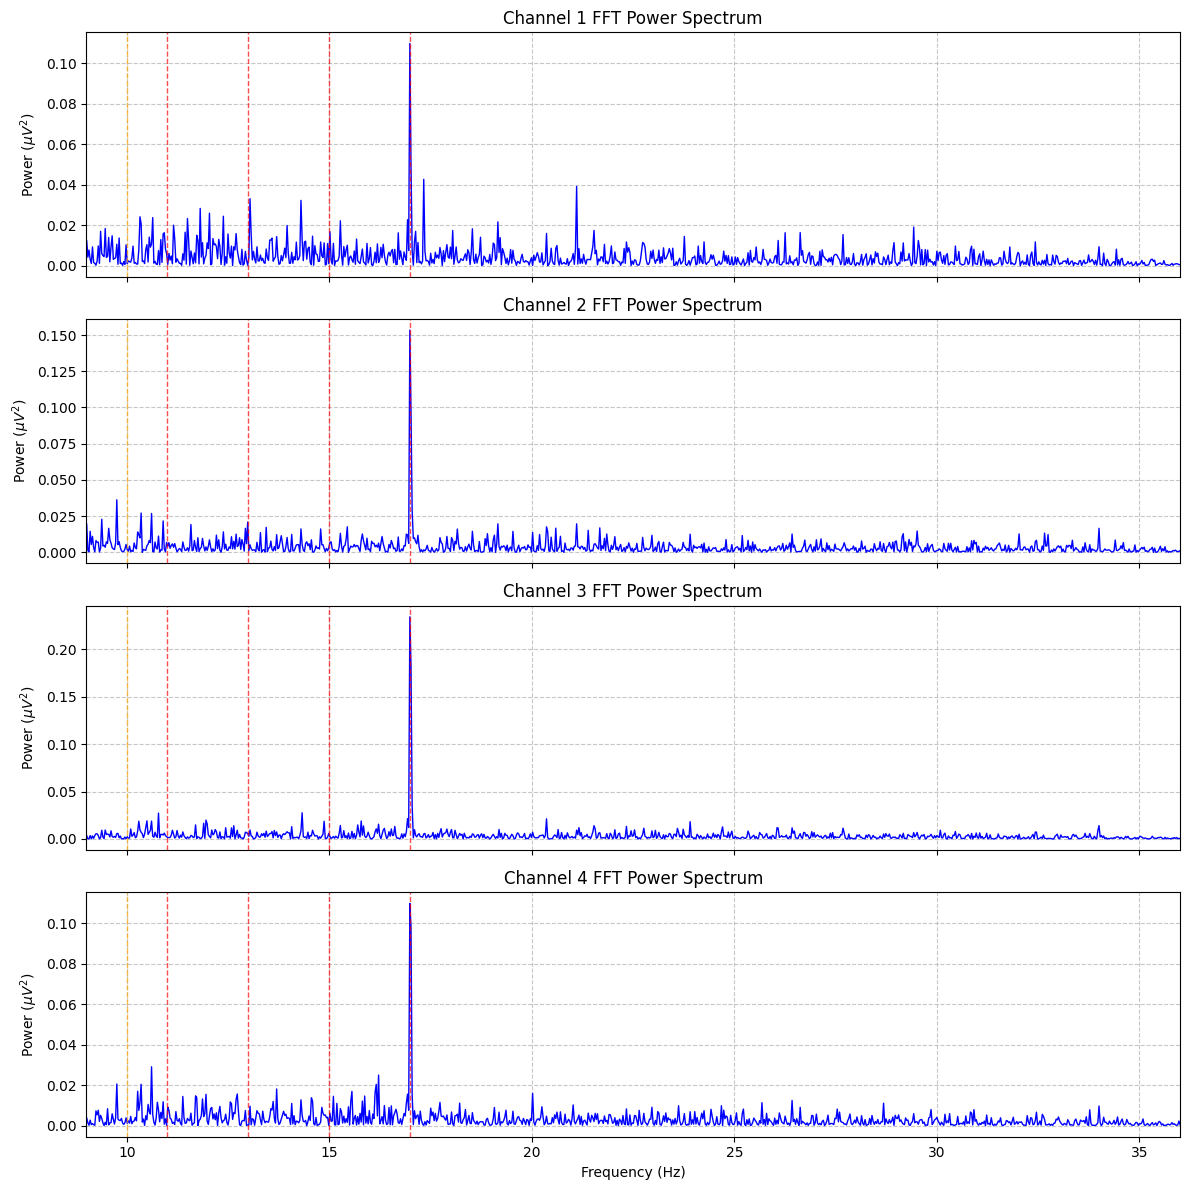

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq

# 1. Define signal parameters
sr = 200  # Sampling rate in Hz
n_samples = eeg_filtered.shape[0]
n_channels = eeg_filtered.shape[1]

# 2. Generate the frequency axis
# fftfreq returns both positive and negative frequencies
freqs = fftfreq(n_samples, 1/sr)

# We only need the positive half of the spectrum for plotting
pos_freqs = freqs[:n_samples//2]

fig, axes = plt.subplots(n_channels, 1, figsize=(12, 12), sharex=True)

# 4. Rectangular-window FFT of the whole record.
for ch in range(n_channels):
    channel_data = eeg_filtered[:, ch]
    channel_data = channel_data - np.mean(channel_data)

    fft_values = fft(channel_data)
    # One-sided power. Raw |FFT|² has units µV²·samples²; dividing by N²
    # and doubling the positive bins reports each line in µV².
    power_spectrum = np.abs(fft_values[:n_samples//2]) ** 2
    power_spectrum[1:] *= 2.0 / (n_samples ** 2)

    # Plot from index 1 onward to explicitly drop the 0 Hz spike
    axes[ch].plot(pos_freqs[1:], power_spectrum[1:], color='b', linewidth=1)
    axes[ch].set_title(f'Channel {ch + 1} FFT Power Spectrum')
    axes[ch].set_ylabel(r'Power ($\mu V^2$)')
    axes[ch].grid(True, linestyle='--', alpha=0.7)
    axes[ch].set_xlim(bp_low, bp_high)
    for f in target_freqs:
        axes[ch].axvline(
            f, color='orange' if f == dummy_freq else 'r',
            linestyle='--', alpha=0.7, linewidth=1)

# 5. Formatting
axes[-1].set_xlabel('Frequency (Hz)')

# Zoom in on the frequency band relevant to SSVEP (e.g., 0 to 50 Hz)
plt.tight_layout()
plt.show()

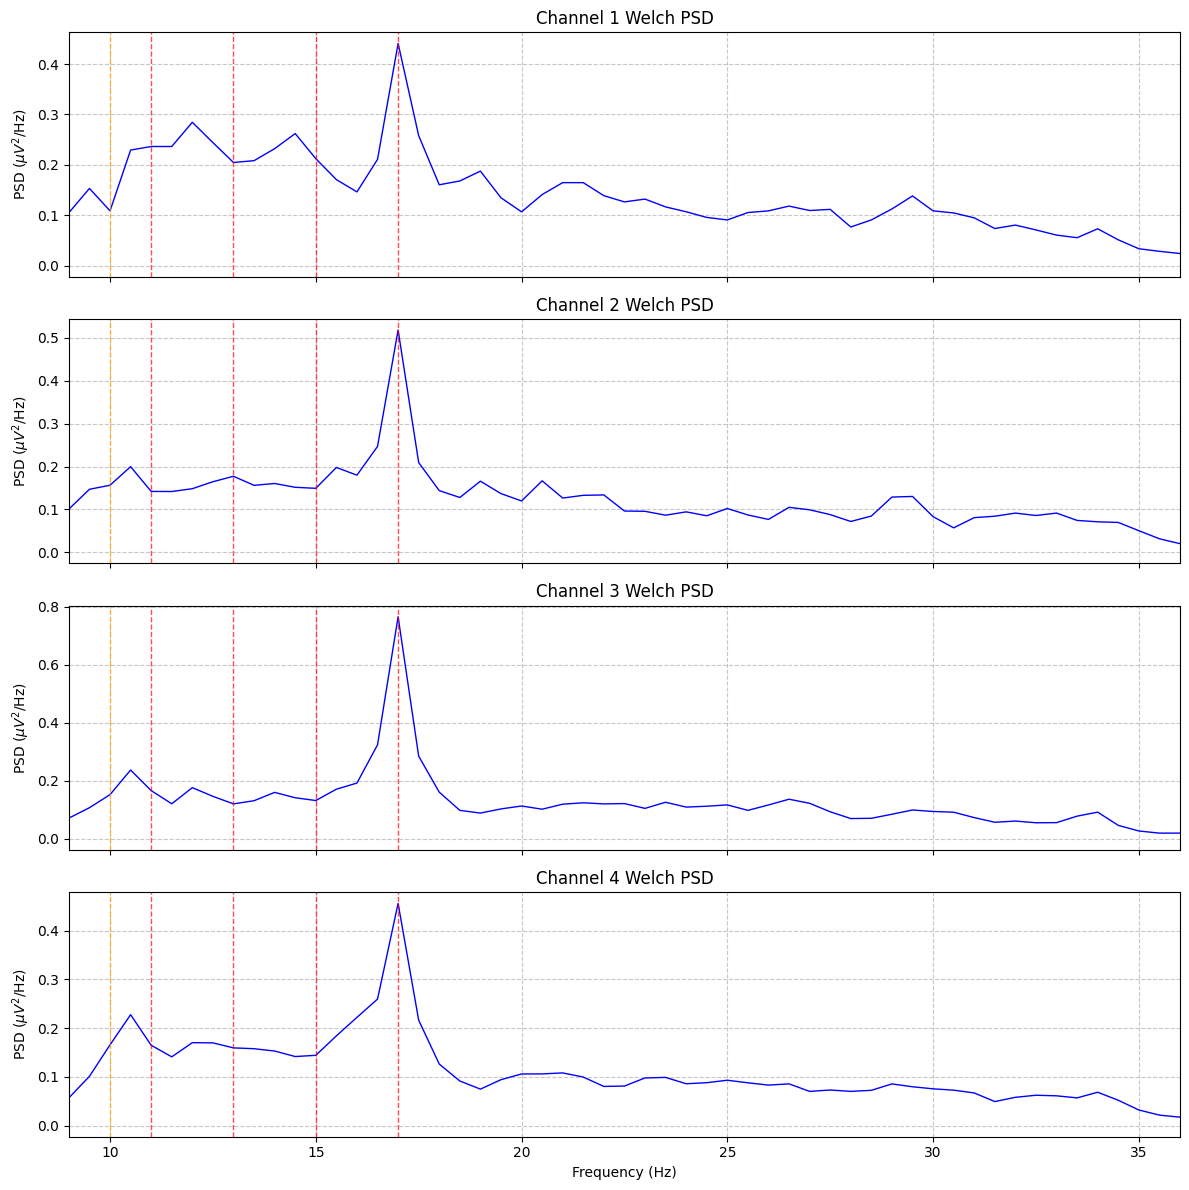

In [7]:
from scipy.signal import welch

# Welch PSD of the same filtered recording. scaling='density' makes the
# one-sided spectrum a density: the values are µV^2/Hz, and integrating
# over frequency recovers the variance of the windowed signal.
# A 2 s Hann segment (0.5 Hz resolution, 50% overlap) is what turns the
# rectangular-FFT spike comb into the background envelope.
n_samples = eeg_filtered.shape[0]
n_channels = eeg_filtered.shape[1]
nperseg = min(2 * sr, n_samples)

fig, axes = plt.subplots(n_channels, 1, figsize=(12, 12), sharex=True)
for ch in range(n_channels):
    freqs_w, psd = welch(
        eeg_filtered[:, ch],
        fs=sr,
        window='hann',
        nperseg=nperseg,
        noverlap=nperseg // 2,
        detrend='constant',
        scaling='density',
    )
    axes[ch].plot(freqs_w, psd, color='b', linewidth=1)
    axes[ch].set_title(f'Channel {ch + 1} Welch PSD')
    axes[ch].set_ylabel(r'PSD ($\mu V^2$/Hz)')
    axes[ch].grid(True, linestyle='--', alpha=0.7)
    axes[ch].set_xlim(bp_low, bp_high)
    for f in target_freqs:
        axes[ch].axvline(
            f, color='orange' if f == dummy_freq else 'r',
            linestyle='--', alpha=0.7, linewidth=1)

axes[-1].set_xlabel('Frequency (Hz)')
plt.tight_layout()
plt.show()


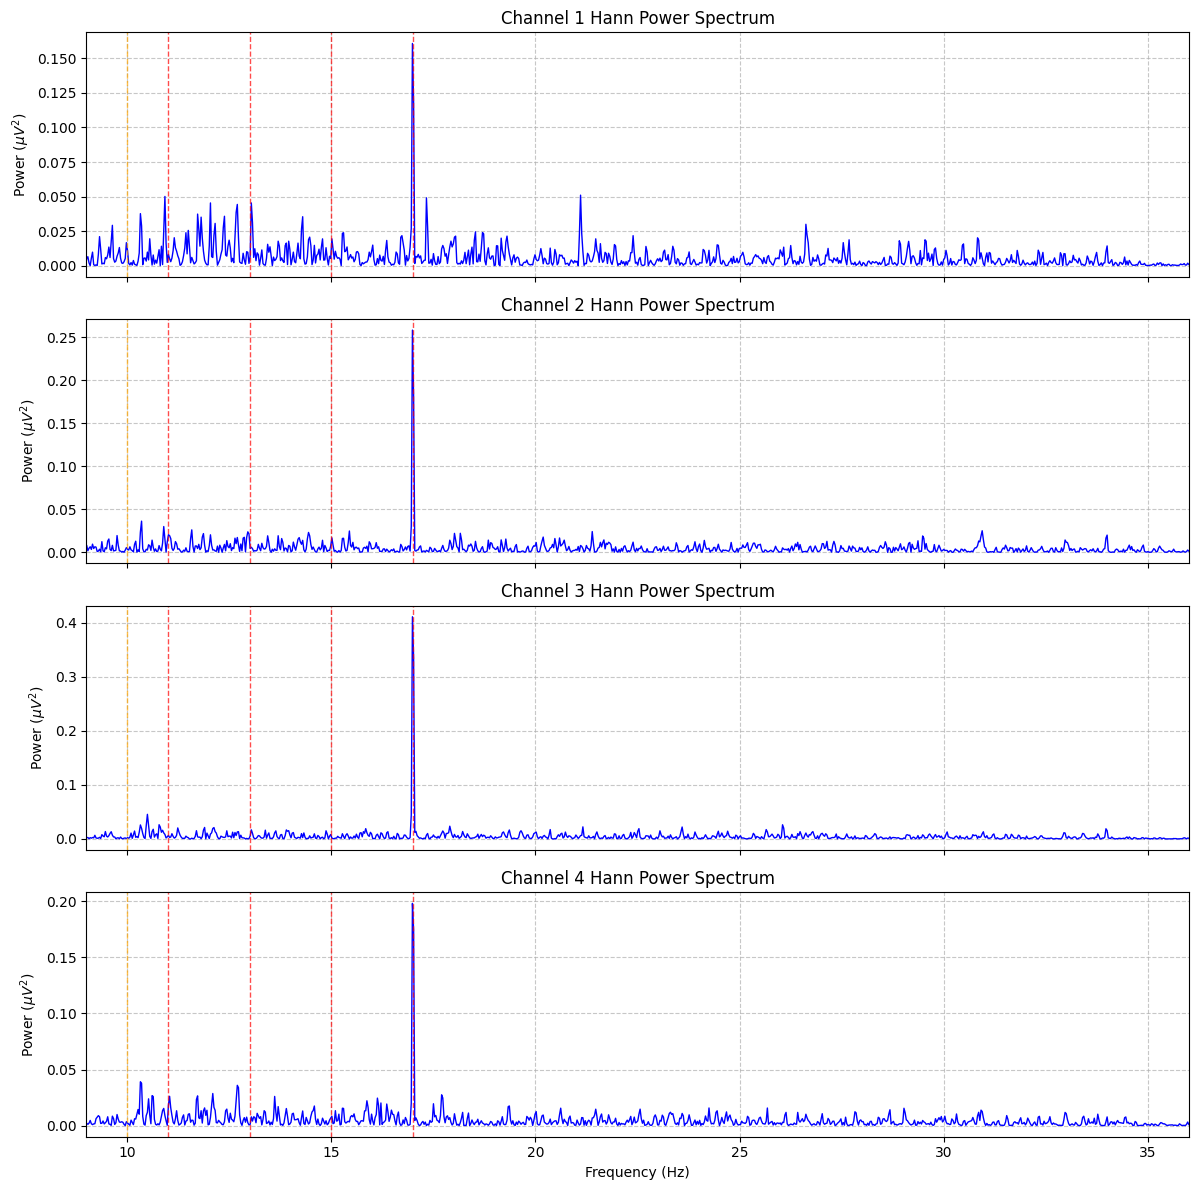

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft, fftfreq

# Hann-windowed power spectrum of the whole record. Same binning the SNR uses.
# The axis is scaled to µV²; SNR itself is a ratio and is unchanged by that scale.
sr = 200
n_samples = eeg_filtered.shape[0]
n_channels = eeg_filtered.shape[1]
taper = np.hanning(n_samples)
hann_scale = np.sum(taper)

# 3. Set up the plotting grid (4 rows, 1 column)
fig, axes = plt.subplots(n_channels, 1, figsize=(12, 12), sharex=True)

# 4. Hann-windowed power spectrum of the whole record. Same spectrum the SNR uses.
for ch in range(n_channels):
    channel_data = eeg_filtered[:, ch]
    channel_data = (channel_data - np.mean(channel_data)) * taper

    fft_values = fft(channel_data)
    pos_freqs = fftfreq(n_samples, 1 / sr)[:n_samples // 2]
    power_spectrum = np.abs(fft_values[:n_samples // 2]) ** 2
    # Divide by the squared sum of the Hann window so a tone is reported in µV².
    power_spectrum[1:] *= 2.0 / (hann_scale ** 2)

    non_zero_idx = pos_freqs > 0
    axes[ch].plot(pos_freqs[non_zero_idx], power_spectrum[non_zero_idx], color='b', linewidth=1)
    axes[ch].set_title(f'Channel {ch + 1} Hann Power Spectrum')
    axes[ch].set_ylabel(r'Power ($\mu V^2$)')
    axes[ch].grid(True, linestyle='--', alpha=0.7)
    axes[ch].set_xlim(bp_low, bp_high)
    for f in target_freqs:
        axes[ch].axvline(
            f, color='orange' if f == dummy_freq else 'r',
            linestyle='--', alpha=0.7, linewidth=1)

# 5. Formatting
axes[-1].set_xlabel('Frequency (Hz)')

plt.tight_layout()
plt.show()


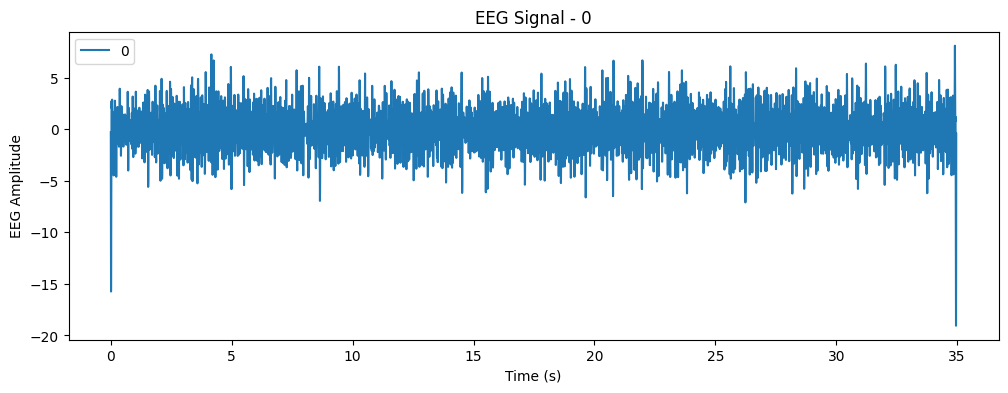

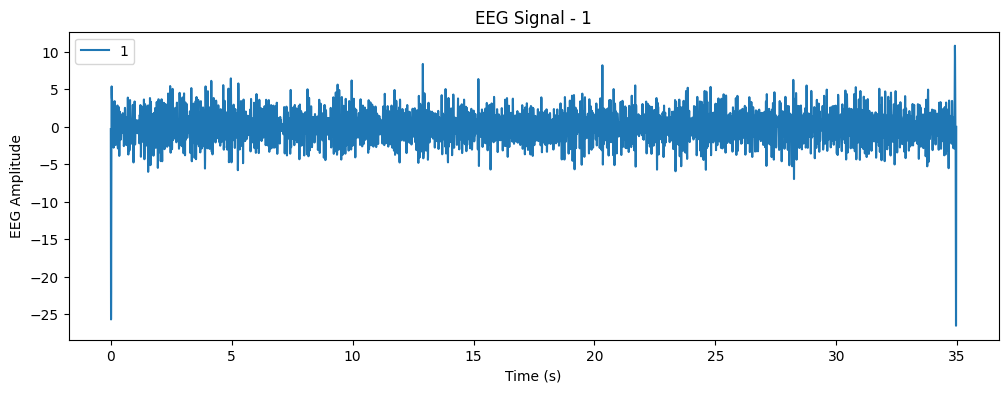

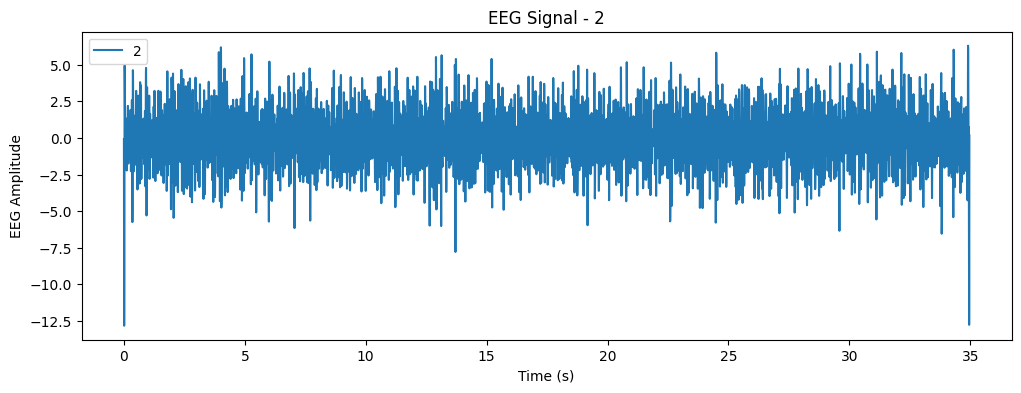

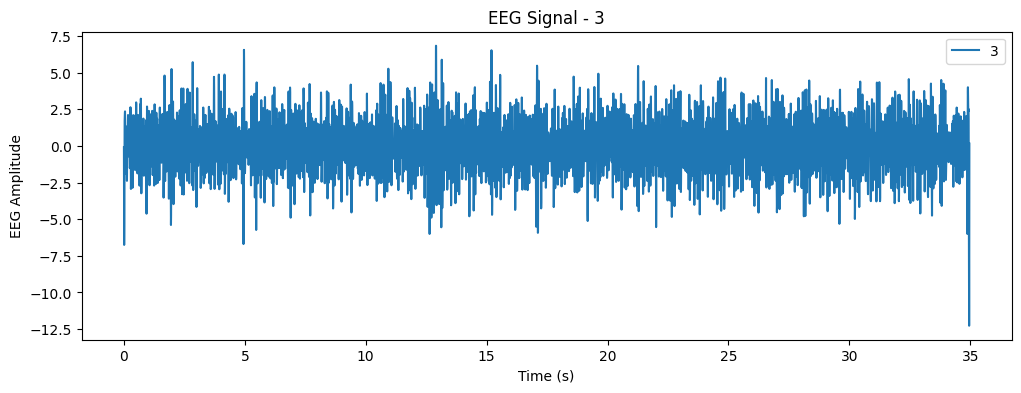

In [9]:
for channel in range(4):
    plt.figure(figsize=(12, 4))
    plt.plot(timestamps, eeg_filtered[:, channel], label=channel)
    plt.xlabel('Time (s)')
    plt.ylabel('EEG Amplitude')
    plt.title(f'EEG Signal - {channel}')
    plt.legend()
    plt.show()


In [10]:
windows = []
window_size = 5 * sr  # seconds * 200 Hz
step_size = 5 * sr     # seconds * 200 Hz
window_sec = window_size / sr
if window_sec + 1e-9 < min_window_sec:
    print(
        f"Window is {window_sec:.2f} s. Noise bins overlap the next scored line "
        f"below {min_window_sec:.2f} s."
    )

# Added +1 to ensure the final window is captured if it fits perfectly
for start in range(0, len(eeg_filtered) - window_size + 1, step_size):
    end = start + window_size
    window = eeg_filtered[start:end, :]
    windows.append(window)

print(f"Created {len(windows)} windows")
print(f"Each window shape: {windows[0].shape}")

Created 6 windows
Each window shape: (1000, 4)


In [11]:
def SNR(power_spectrum, freqs, target_freq, n=3, guard=2):
    """Peak SNR at target_freq.

    Noise bins start `guard` bins off the candidate so the Hann main lobe is not
    counted as noise. A line fit through those bins is the local baseline.
    A shoulder, where the candidate is not above that line, scores 0.
    Otherwise SNR = power(f) / max(mean(left), mean(right)).
    """
    idx = int(np.argmin(np.abs(freqs - target_freq)))
    far = guard + n - 1
    left_lo = idx - far
    left_hi = idx - guard + 1
    right_lo = idx + guard
    right_hi = idx + far + 1
    if left_lo < 0 or right_hi > len(power_spectrum):
        return 0.0

    left = power_spectrum[left_lo:left_hi]
    right = power_spectrum[right_lo:right_hi]
    if left.size < n or right.size < n:
        return 0.0

    signal = float(power_spectrum[idx])
    x = np.concatenate([freqs[left_lo:left_hi], freqs[right_lo:right_hi]])
    y = np.concatenate([left, right])
    slope, intercept = np.polyfit(x, y, 1)
    excess = signal - (slope * float(freqs[idx]) + intercept)
    if excess <= 0.0:
        return 0.0

    noise = max(float(np.mean(left)), float(np.mean(right)))
    if noise <= 0.0:
        return 0.0
    return signal / noise

Window 1 | Max Freq: 17 Hz | Gate Ratio: 16.62


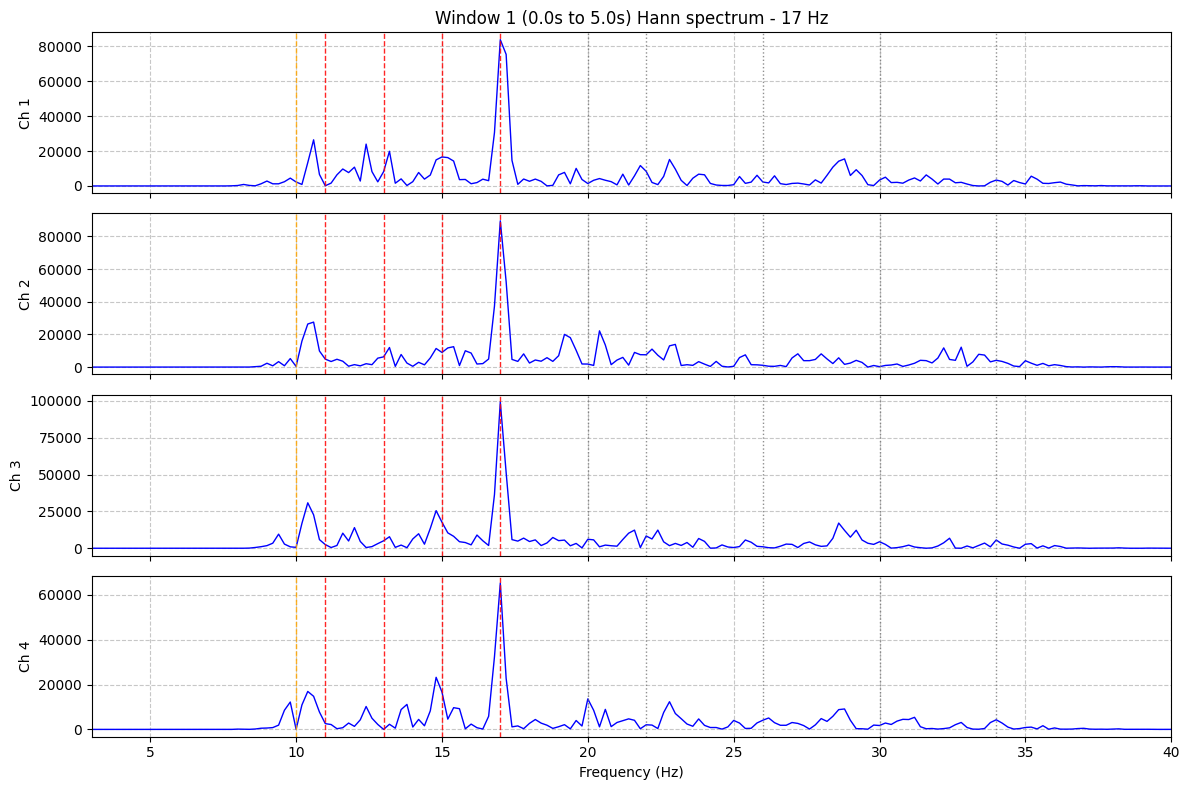

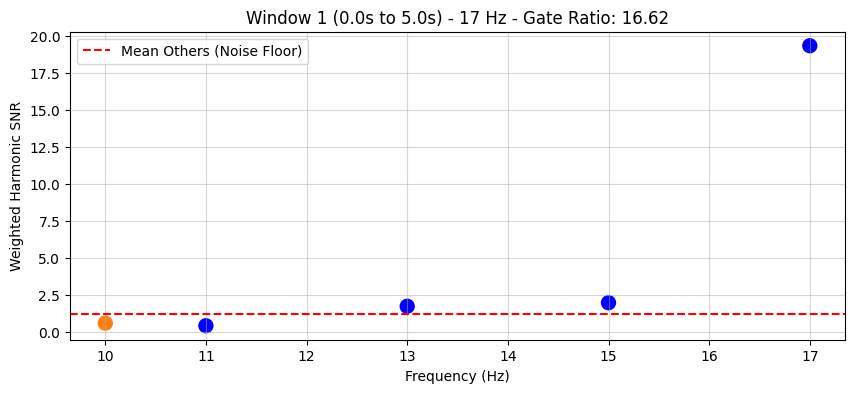

Window 2 | Max Freq: 17 Hz | Gate Ratio: 4.89


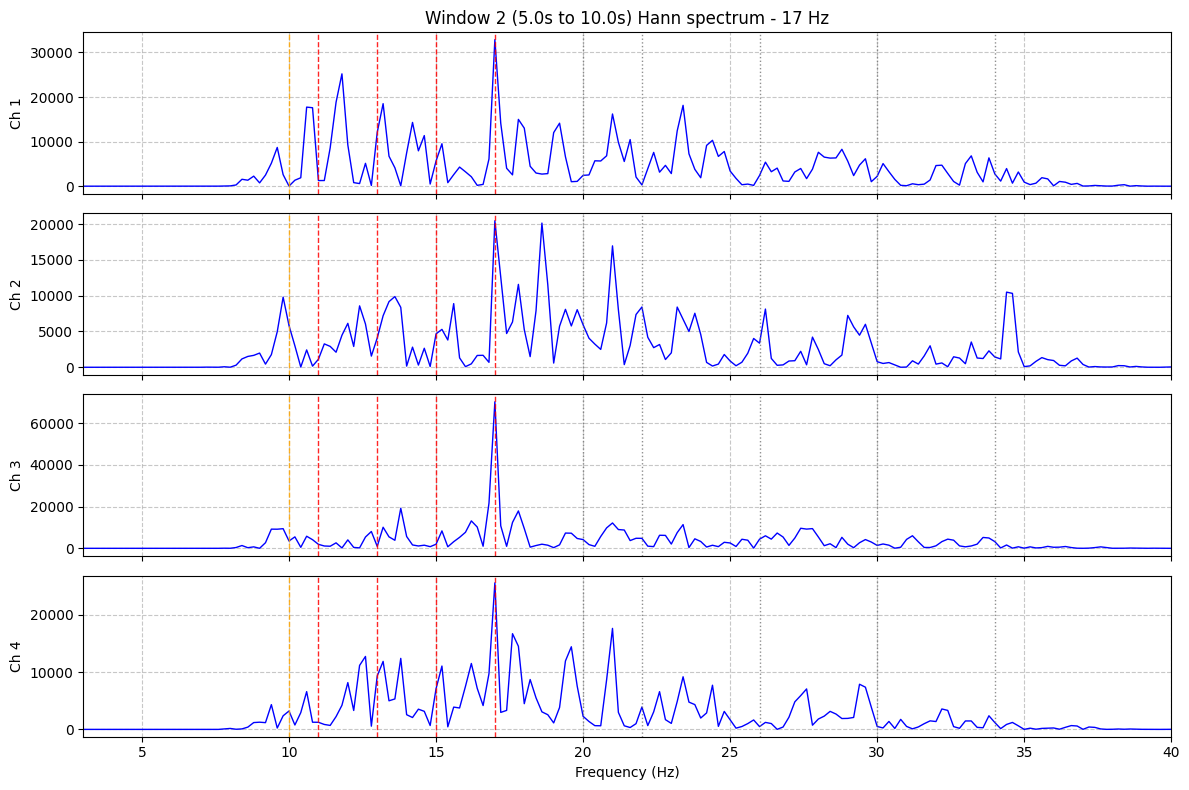

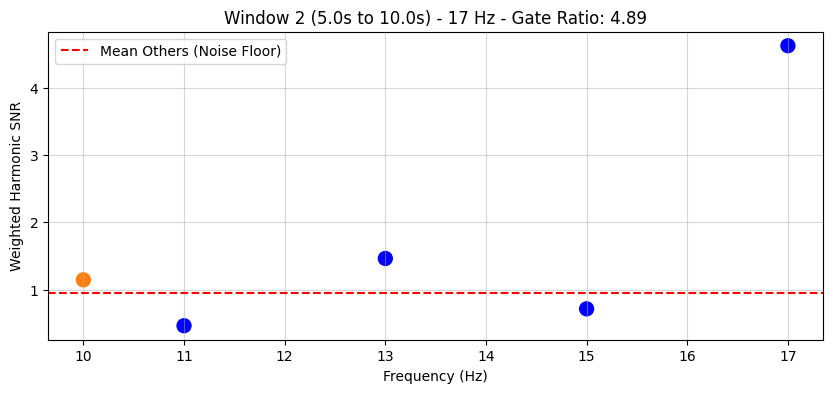

Window 3 | Max Freq: 17 Hz | Gate Ratio: 4.80


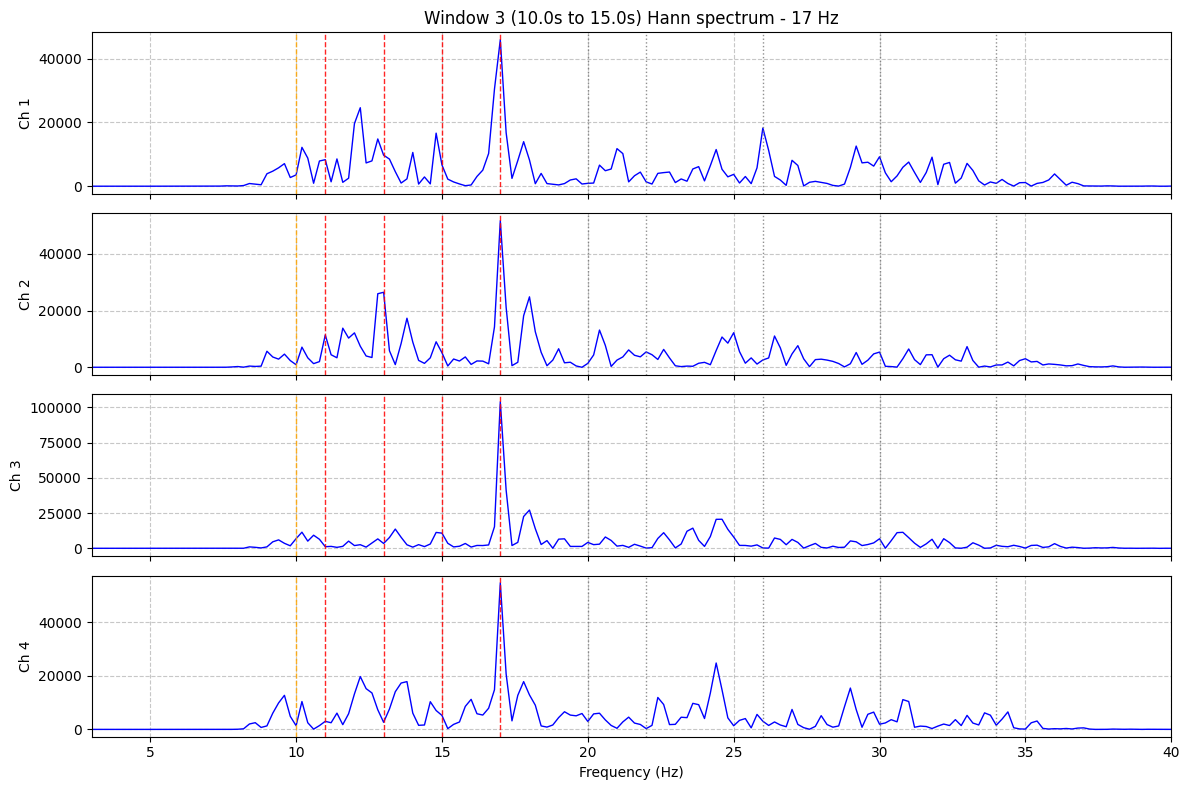

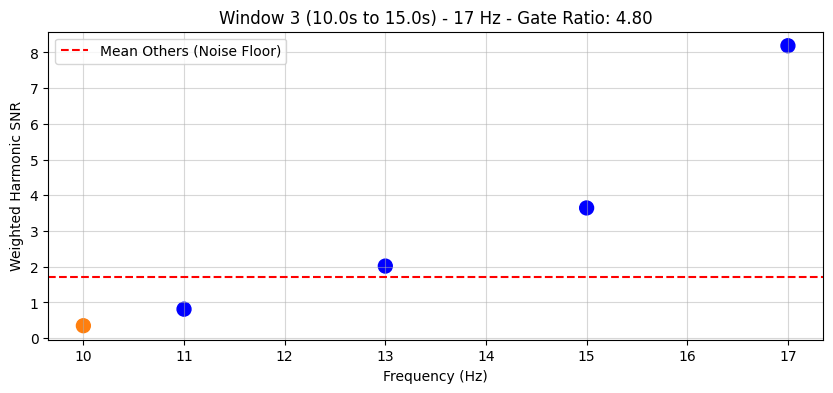

Window 4 | Max Freq: 17 Hz | Gate Ratio: 14.13


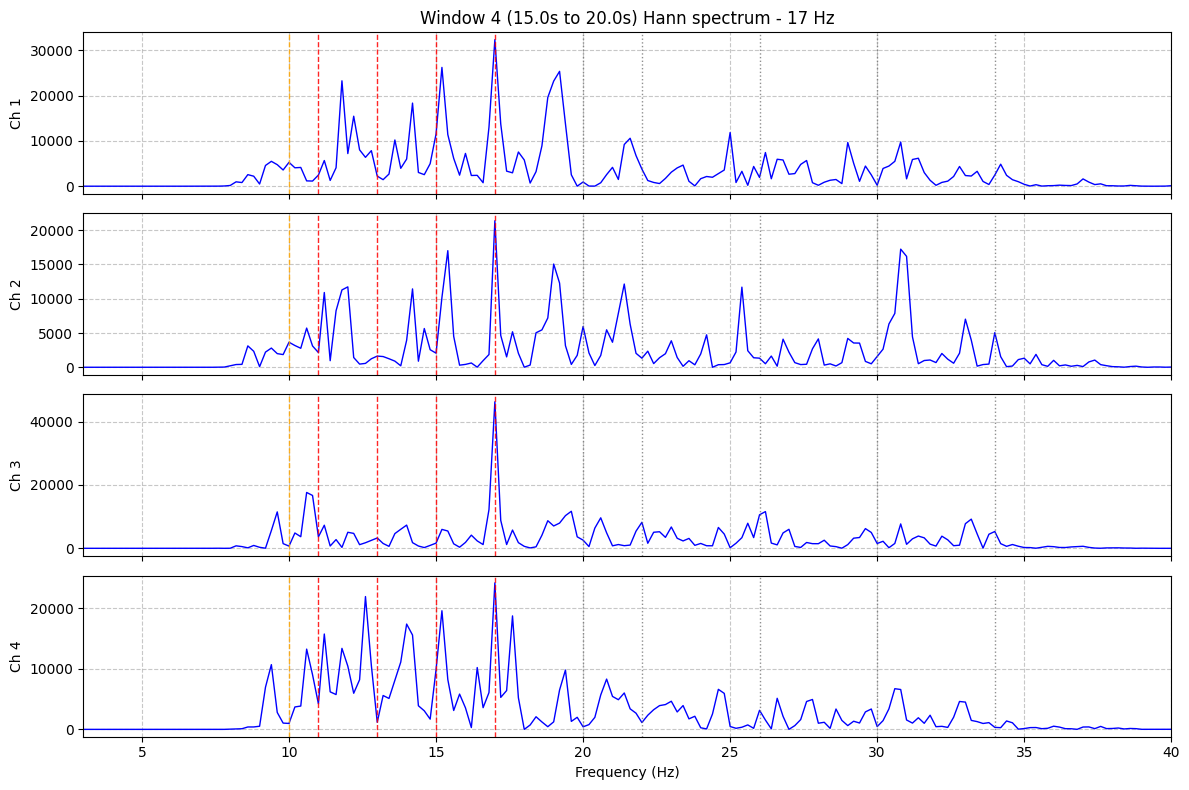

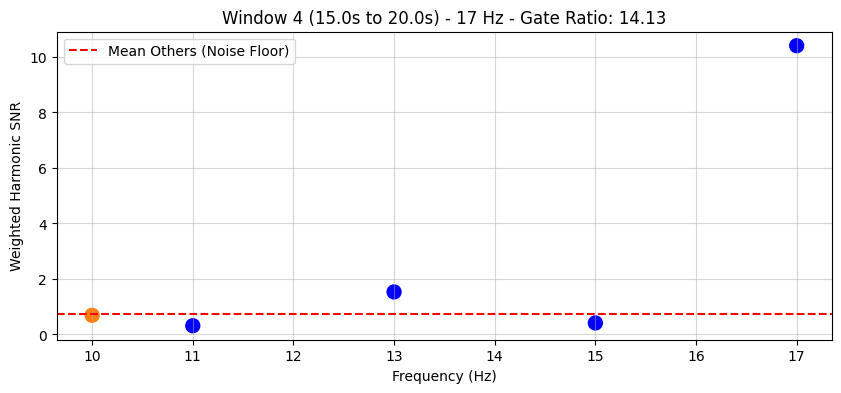

Window 5 | Max Freq: 17 Hz | Gate Ratio: 8.65


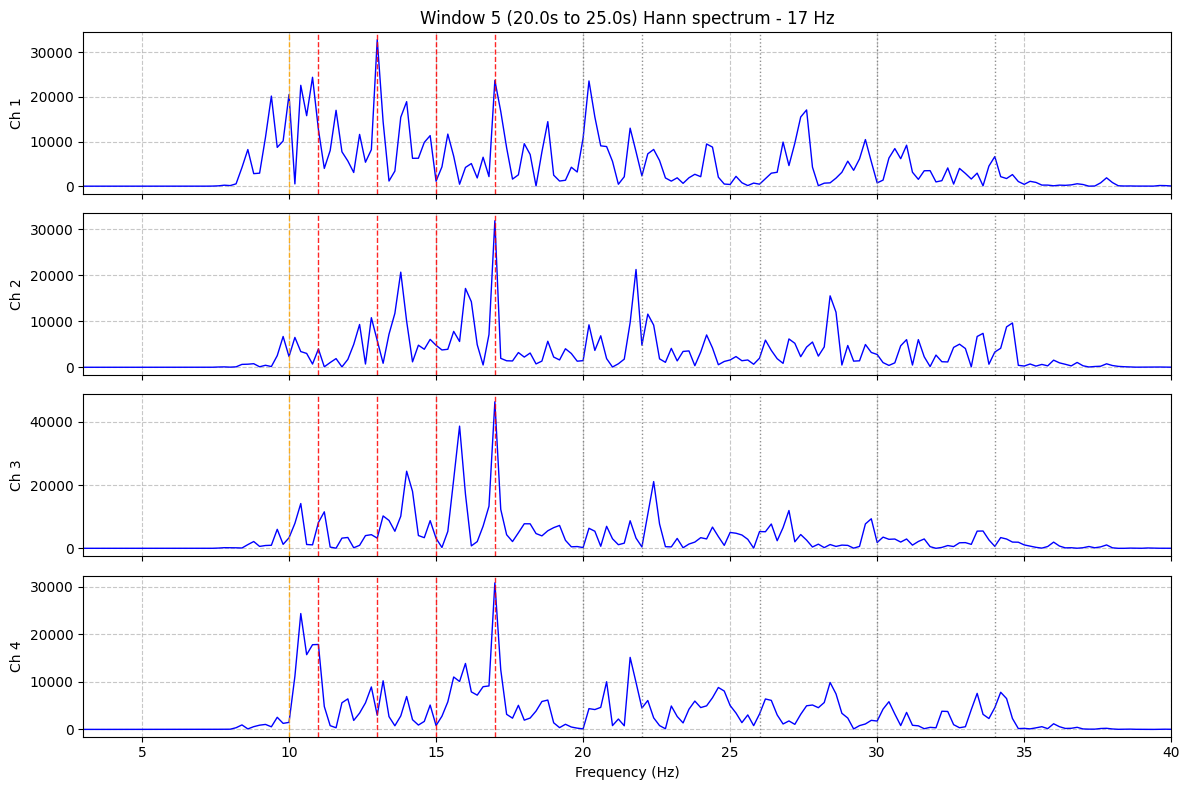

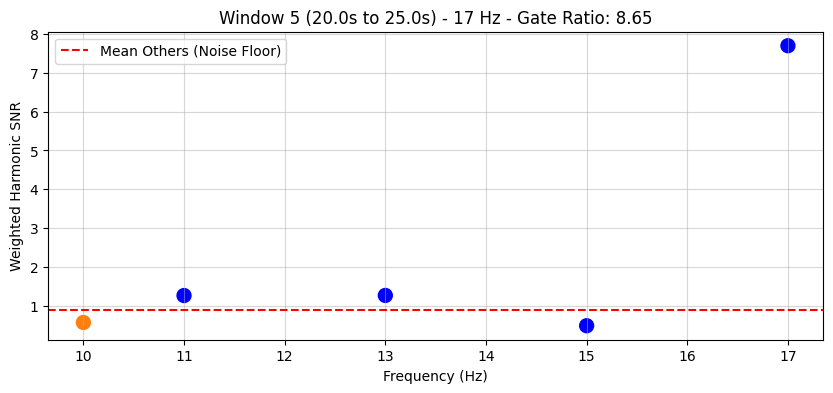

Window 6 | Max Freq: 17 Hz | Gate Ratio: 3.36


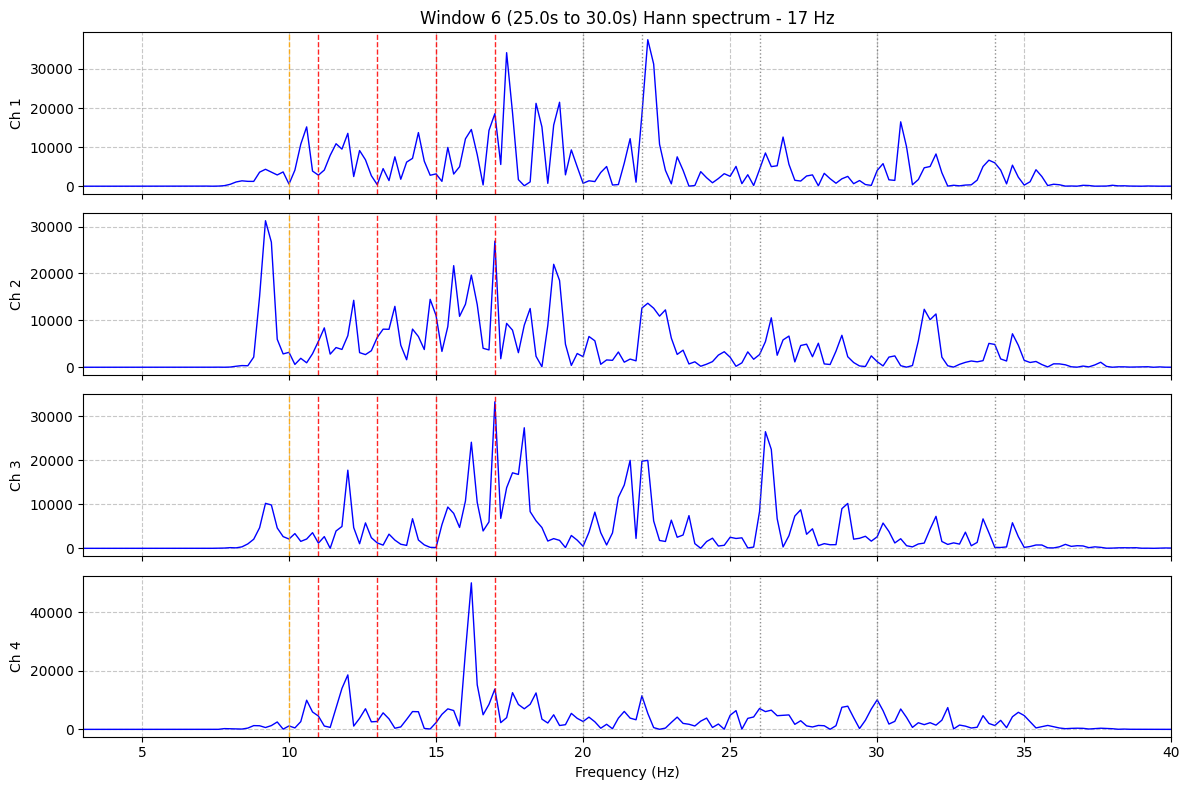

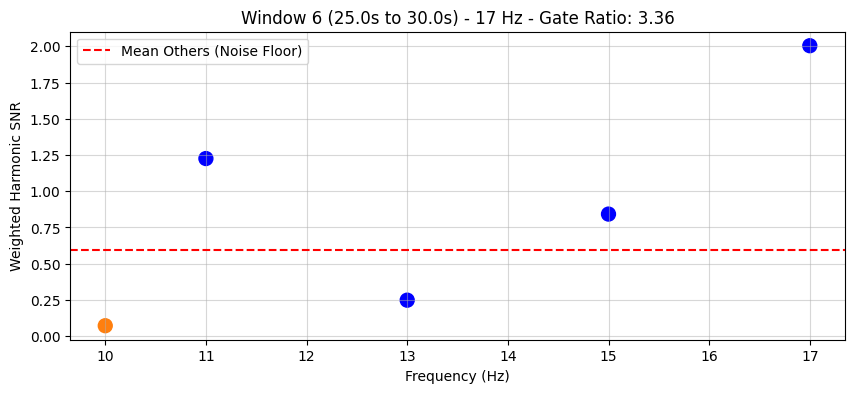

In [12]:
from scipy.fft import fft, fftfreq
import numpy as np
import matplotlib.pyplot as plt

# Assuming 'windows' and 'sr' are defined earlier
n_samples = windows[0].shape[0]
n_channels = windows[0].shape[1]

# 1. Define Fixed Channel Weights (e.g., O1, O2 get 70% of the weight, PO7, PO8 get 30%)
# Adjust the index positions to match your actual data array order
channel_weights = np.array([0.15, 0.35, 0.35, 0.15])

gate_ratios = []

# Process and plot each window separately
for i, window in enumerate(windows):
    # window_powers will store a list of 4 channel scores for each frequency
    window_powers = {freq: [] for freq in target_freqs}
    n_samples = window.shape[0]
    taper = np.hanning(n_samples)
    spectra = []
    positive_freqs = None

    for ch in range(n_channels):
        channel_data = window[:, ch]
        channel_data = (channel_data - np.mean(channel_data)) * taper

        fft_values = fft(channel_data)
        fft_freqs = fftfreq(n_samples, 1/sr)

        power_spectrum = np.abs(fft_values[:n_samples//2]) ** 2
        positive_freqs = fft_freqs[:n_samples//2]
        spectra.append(power_spectrum)

        for target_freq in target_freqs:
            snr_1 = SNR(power_spectrum, positive_freqs, target_freq, n=snr_n, guard=snr_guard)
            snr_2 = SNR(power_spectrum, positive_freqs, target_freq * 2.0, n=snr_n, guard=snr_guard)

            # Harmonic Summation
            H_snr = snr_1 + 0.5 * snr_2
            window_powers[target_freq].append(H_snr)

    # 2. Weighted Average across channels for this window
    weighted_avg_powers = [np.average(window_powers[freq], weights=channel_weights) for freq in target_freqs]
    
    # 3. Calculate the Gate Ratio
    max_score = np.max(weighted_avg_powers)
    max_idx = np.argmax(weighted_avg_powers)
    
    # Extract the scores of the non-target frequencies to find the noise floor
    other_scores = [score for j, score in enumerate(weighted_avg_powers) if j != max_idx]
    mean_other_scores = np.mean(other_scores)
    gate_ratio = 0.0 if mean_other_scores <= 0.0 else max_score / mean_other_scores
    gate_ratios.append(gate_ratio)

    winner = target_freqs[max_idx]
    winner_label = "no input" if winner == dummy_freq else f"{winner:g} Hz"
    start_time = (i * step_size) / sr if 'step_size' in locals() else 0
    end_time = start_time + (n_samples / sr)

    # Print the Gate Ratio for observation
    print(f"Window {i+1} | Max Freq: {winner_label} | Gate Ratio: {gate_ratio:.2f}")

    # Hann spectrum actually scored for this window. Red lines are boards, orange is the
    # dummy, dotted lines are the second harmonics.
    fig, axes = plt.subplots(n_channels, 1, figsize=(12, 8), sharex=True)
    if n_channels == 1:
        axes = [axes]
    nonzero = positive_freqs > 0
    for ch in range(n_channels):
        axes[ch].plot(positive_freqs[nonzero], spectra[ch][nonzero], color='b', linewidth=1)
        axes[ch].set_ylabel(f'Ch {ch + 1}')
        axes[ch].set_xlim(3, 40)
        axes[ch].grid(True, linestyle='--', alpha=0.7)
        for f in target_freqs:
            axes[ch].axvline(
                f, color='orange' if f == dummy_freq else 'r',
                linestyle='--', alpha=0.85, linewidth=1)
            axes[ch].axvline(2.0 * f, color='0.45', linestyle=':', alpha=0.8, linewidth=1)
    axes[0].set_title(
        f'Window {i+1} ({start_time:.1f}s to {end_time:.1f}s) Hann spectrum - {winner_label}'
    )
    axes[-1].set_xlabel('Frequency (Hz)')
    plt.tight_layout()
    plt.show()

    plt.figure(figsize=(10, 4))
    colors = ['tab:orange' if f == dummy_freq else 'b' for f in target_freqs]
    plt.scatter(target_freqs, weighted_avg_powers, marker='o', c=colors, s=100)
    plt.axhline(mean_other_scores, color='r', linestyle='--', label='Mean Others (Noise Floor)')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Weighted Harmonic SNR')
    plt.title(f'Window {i+1} ({start_time:.1f}s to {end_time:.1f}s) - {winner_label} - Gate Ratio: {gate_ratio:.2f}')
    plt.grid(True, alpha=0.5)
    plt.legend()
    plt.show()

# After the loop, you can analyze `gate_ratios` to find your resting state threshold
# e.g., threshold = np.mean(resting_gate_ratios) + 2.5 * np.std(resting_gate_ratios)